In [1]:
# !pip install -q -U langchain-nebius langchain langgraph rich python-dotenv tavily-python

In [2]:
from dotenv import load_dotenv
from langchain_community.tools import TavilySearchResults
import os
from langgraph.prebuilt import ToolNode
from rich.console import Console  # Console styling
from rich.markdown import Markdown  # Render markdown in terminal
from rich.syntax import Syntax

from common import LLM_MODEL, API_BASE, API_KEY

load_dotenv(override=True)
console = Console()

# Initialize the tool. We can set the max number of results to keep the context concise.
search_tool = TavilySearchResults(max_results=2)
# It's crucial to give the tool a clear name and description for the agent
search_tool.name = "web_search"
search_tool.description = "A tool that can be used to search the internet for up-to-date information on any topic, including news, events, and current affairs."
tools = [search_tool]

# Let's test the tool directly to see its output format
print("\n--- Testing the tool directly ---")
test_query = "What was the score of the last Super Bowl?"
test_result = search_tool.invoke({"query": test_query})
console.print(f"[bold green]Query:[/bold green] {test_query}")
console.print("\n[bold green]Result:[/bold green]")
console.print(test_result)

API_BASE:https://api-ad-ops-prod-advibe.nioint.com
model:claude-deepseek-v4-pro（ADVibe）

--- Testing the tool directly ---


/var/folders/5r/1m67q6wn6yjbm75v3ydwx8yc0000gq/T/ipykernel_76076/2024659972.py:15: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  search_tool = TavilySearchResults(max_results=2)


Query: What was the score of the last Super Bowl?

Result:

[
    {
        'title': 'List of Super Bowl champions - Wikipedia',
        'url': 'https://en.wikipedia.org/wiki/List_of_Super_Bowl_champions',
        'content': 'Super Bowl championships| Game | Date (season) | Winning team | Score | Losing team | Score | 
Venue | City | Attendance | Referee | Ref. |\n ---  ---  ---  ---  --- \n| I ( | Jan 15, 1967 (1966 AFL/1966 NFL) |
Green Bay Packersn (1, 1–0) | 35 | Kansas City Chiefsa (1, 0–1) | 10 | Los Angeles Memorial Coliseum | Los Angeles,
California( | 61,946 | Norm Schachter | ( |\n| II ( | Jan 14, 1968 (1967 AFL/1967 NFL) | Green Bay Packersn (2, 
2–0) | 33 | Oakland Raidersa (1, 0–1) | 14 | Miami Orange Bowl | Miami, Florida( | 75,546 | Jack Vest | ( |\n| III 
( | Jan 12, 1969 (1968 AFL/1968 NFL) | New York Jetsa (1, 1–0) | 16 | Baltimore Coltsn (1, 0–1) | 7 | Miami Orange 
Bowl (2) | Miami, Florida (2)( | 75,389 | Tom Bell "Tommy Bell (American football official)") | ( |\n| IV ( | Jan 
11, 1970 (1969 AFL/1969 NFL) | Kansas City Chiefsa (2, 1–1) | 23 | Minnesota Vikingsn (1, 0–1) | 7 | Tulane Stadium
| New Orleans, Louisiana | 80,562 | John McDonough "John McDonough (American football referee)") | ( |\n| V | Jan 
17, 1971 (1970) | Baltimore ColtsA (2, 1–1) | 16 | Dallas CowboysN (1, 0–1) | 13 | Miami Orange Bowl (3) | Miami, 
Florida (3)( | 79,204 | Norm Schachter | ( |\n| VI | Jan 16, 1972 (1971) | Dallas CowboysN (2, 1–1) | 24 | Miami 
DolphinsA (1, 0–1) | 3 | Tulane Stadium (2) | New Orleans, Louisiana (2) | 81,023 | Jim Tunney "Jim Tunney 
(American football)") | ( |\n| VII | Jan 14, 1973 (1972) | Miami DolphinsA (2, 1–1) | 14 | Washington RedskinsN (1,
0–1) | 7 | Los Angeles Memorial Coliseum (2) | Los Angeles, California (2)( | 90,182 | Tom Bell "Tommy Bell 
(American football official)") | ( || VIII | Jan 13, 1974 (1973) | Miami DolphinsA (3, 2–1) | 24 | Minnesota 
VikingsN (2, 0–2) | 7 | Rice Stadium "Rice Stadium (Rice University)")( | Houston, Texas | 71,882 | Ben Dreith | ( 
|\n| IX | Jan 12, 1975 (1974) | Pittsburgh SteelersA (1, 1–0) | 16 | Minnesota VikingsN (3, 0–3) | 6 | Tulane 
Stadium (3) | New Orleans, Louisiana (3) | 80,997 | Bernie Ulman | ( |\n| X | Jan 18, 1976 (1975) | Pittsburgh 
SteelersA (2, 2–0) | 21 | Dallas CowboysN (3, 1–2)( | 17 | Miami Orange Bowl (4) | Miami, Florida (4)( | 80,187 | 
Norm Schachter | ( |\n| XI | Jan 9, 1977 (1976) | Oakland RaidersA (2, 1–1) | 32 | Minnesota VikingsN (4, 0–4) | 14
| Rose Bowl "Rose Bowl (stadium)")( | Pasadena, California (3)( | 103,438 | Jim Tunney "Jim Tunney (American 
football)") | ( |\n| XII | Jan 15, 1978 (1977) | Dallas CowboysN (4, 2–2) | 27 | Denver BroncosA (1, 0–1) | 10 | 
Louisiana Superdome( | New Orleans, Louisiana (4) | 76,400 | Jim Tunney "Jim Tunney (American football)") | ( |\n| 
XIII | Jan 21, 1979 (1978) | Pittsburgh SteelersA (3, 3–0) | 35 | Dallas CowboysN (5, 2–3) | 31 | Miami Orange Bowl
(5) | Miami, Florida (5)( | 79,484 | Pat Haggerty "Pat Haggerty (American football official)") | ( |\n| XIV | Jan 
20, 1980 (1979) | Pittsburgh SteelersA (4, 4–0) | 31 | Los Angeles RamsN (1, 0–1) | 19 | Rose Bowl "Rose Bowl 
(stadium)") (2)( 7]]( | Pasadena, California (4)( | 103,985 | Fred Silva | ( |\n| XV | Jan 25, 1981 (1980) | 
Oakland RaidersA (3, 2–1)( | 27 | Philadelphia EaglesN (1, 0–1) | 10 | Louisiana Superdome (2)( | New Orleans, 
Louisiana (5) | 76,135 | Ben Dreith | ( || XVI | Jan 24, 1982 (1981) | San Francisco 49ersN (1, 1–0) | 26 | 
Cincinnati BengalsA (1, 0–1) | 21 | Pontiac Silverdome | Pontiac, Michigan( | 81,270 | Pat Haggerty "Pat Haggerty 
(American football official)") | ( |\n| XVII | Jan 30, 1983 (1982) | Washington RedskinsN (2, 1–1) | 27 | Miami 
DolphinsA (4, 2–2) | 17 | Rose Bowl "Rose Bowl (stadium)") (3)( | Pasadena, California (5)( | 103,667 | Jerry 
Markbreit | ( |\n| XVIII | Jan 22, 1984 (1983) | Los Angeles RaidersA (4, 3–1) | 38 | Washington RedskinsN (3, 1–2)
| 9 | Tampa Stadium | Tampa, Florida | 72,980 | Gene Barth | ( |\n| XIX | Jan 20, 1985 (1984) | San Franci

In [3]:
from typing import Annotated


from langchain_anthropic import ChatAnthropic
from langchain_core.messages import AnyMessage
from langchain_protocol import TypedDict
from langgraph.graph import add_messages


class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

llm = ChatAnthropic(
    model_name=LLM_MODEL,
    api_key=API_KEY,
    base_url=API_BASE,
    max_tokens=16000,
)

llm_with_tools = llm.bind_tools(tools=tools)





In [38]:

def agent_node(state: AgentState):
    """The primary node that calls the LLM to decide the next action."""
    console.print("--- AGENT: Thinking... ---")
    response = llm_with_tools.invoke(state["messages"])
    console.print(f"--- AGENT: Response-----")
    return {"messages": [response]}

# The ToolNode is a pre-built node from LangGraph that executes tools
tool_node = ToolNode(tools)

In [45]:
def router_function(state: AgentState) -> str:
    """Inspects the agent's last message to decide the next step."""
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        # The agent has requested a tool call
        console.print(f"--- ROUTER: Decision is to call a tool. ---")
        return "call_tool"
    else:
        # The agent has provided a final answer
        console.print(f"--- ROUTER: Decision is to finish.---")
        return "__end__"

In [46]:
from langgraph.graph import StateGraph


graph_builder = StateGraph(AgentState)

# Add the nodes
graph_builder.add_node("agent", agent_node)
graph_builder.add_node("call_tool", tool_node)

# Set the entry point
graph_builder.set_entry_point("agent")

# Add the conditional router
graph_builder.add_conditional_edges(
    "agent",
    router_function,
)

# Add the edge from the tool node back to the agent to complete the loop
# graph_builder.add_edge( "agent","call_tool")
graph_builder.add_edge("call_tool", "agent")

# Compile the graph
tool_agent_app = graph_builder.compile()

Tool-using agent graph compiled successfully!


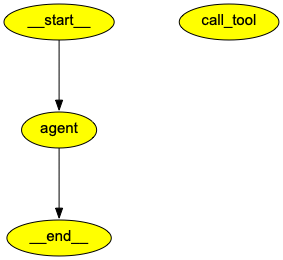

In [47]:
print("Tool-using agent graph compiled successfully!")

# Visualize the graph
try:
    from IPython.display import Image, display
    png_image = tool_agent_app.get_graph().draw_png()
    display(Image(png_image))
except Exception as e:
    print(f"Graph visualization failed: {e}. Please ensure pygraphviz is installed.")

In [48]:
from rich.console import Console  # Console styling
from rich.markdown import Markdown  # Render markdown in terminal
from rich.syntax import Syntax



user_query = "What were the main announcements from Apple's latest WWDC event?"
initial_input = {"messages": [("user", user_query)]}

console.print(f"[bold cyan]🚀 Kicking off Tool Use workflow for request:[/bold cyan] '{user_query}'\n")

for chunk in tool_agent_app.stream(initial_input, stream_mode="values"):
    chunk["messages"][-1].pretty_print()
    console.print("\n---\n")


console.print("\n[bold green]✅ Tool Use workflow complete![/bold green]")

🚀 Kicking off Tool Use workflow for request: 'What were the main announcements from Apple's latest WWDC event?'

================================ Human Message =================================

What were the main announcements from Apple's latest WWDC event?


---

--- AGENT: Thinking... ---

--- AGENT: Response-----

...

--- AGENT: Response-----

--- ROUTER: Decision is to finish.---

================================== Ai Message ==================================

[{'signature': None, 'thinking': "I have good information now. Let me compile a comprehensive answer about WWDC 2026 announcements. Key points:\n\n1. WWDC 2026 happened June 8, 2026, at Apple Park, Tim Cook's last as CEO.\n2. Major announcements:\n- iOS 27, iPadOS 27, macOS 27, watchOS 27, visionOS 27, tvOS 27\n- New Siri AI - rebrand, built on Apple foundation models powered by Google Gemini, conversations, personal context, onscreen awareness, app actions\n- Apple Intelligence upgrades - multiple third-party AI models (ChatGPT, Claude, Gemini)\n- Liquid Glass improvements - adjustable transparency slider, toolbars\n- Performance improvements - apps launch 30% faster, photos 70% faster, compatibility back to iPhone 11\n- New Macs with M5 Ultra chip\n- Camera app updates\n- Child safety tools and parental controls\n- Home app AI-powered camera clip summaries\n- Cross-platform sharing, Health app updates\n

---

✅ Tool Use workflow complete!

In [51]:
from pydantic import BaseModel, Field


class ToolUseEvaluation(BaseModel):
    """Schema for evaluating the agent's tool use and final answer."""
    tool_selection_score: int = Field(description="Score 1-5 on whether the agent chose the correct tool for the task.")
    tool_input_score: int = Field(description="Score 1-5 on how well-formed and relevant the input to the tool was.")
    synthesis_quality_score: int = Field(description="Score 1-5 on how well the agent integrated the tool's output into its final answer.")
    justification: str = Field(description="A brief justification for the scores.")

In [52]:
judge_llm = llm.with_structured_output(ToolUseEvaluation)

# To evaluate, we need to reconstruct the full conversation trace
final_answer = tool_agent_app.invoke(initial_input)
conversation_trace = "\n".join([f"{m.type}: {m.content or ''} {getattr(m, 'tool_calls', '')}" for m in final_answer['messages']])

def evaluate_tool_use(trace: str):
    prompt = f"""You are an expert judge of AI agents. Evaluate the following conversation trace based on the agent's tool use on a scale of 1-5. Provide a brief justification.
    
    Conversation Trace:
    ```
    {trace}
    ```
    """
    return judge_llm.invoke(prompt)

console.print("--- Evaluating Tool Use Performance ---")
evaluation = evaluate_tool_use(conversation_trace)
console.print(evaluation.model_dump())

--- AGENT: Thinking... ---

--- AGENT: Response-----

--- ROUTER: Decision is to call a tool. ---

--- AGENT: Thinking... ---

--- AGENT: Response-----

...

--- AGENT: Thinking... ---

--- AGENT: Response-----

--- ROUTER: Decision is to finish.---

--- Evaluating Tool Use Performance ---

{
    'tool_selection_score': 5,
    'tool_input_score': 5,
    'synthesis_quality_score': 5,
    'justification': 'The agent correctly chose web_search for a time-sensitive question about a recent event 
beyond its knowledge cutoff. The queries were specific, relevant, and progressively refined to gather details 
(e.g., "Apple WWDC 2025 main announcements" and follow-ups on specific OS announcements). The final answer 
synthesized the retrieved information accurately and comprehensively, covering OS naming, Liquid Glass, 
iOS/iPadOS/macOS/watchOS/visionOS/tvOS updates, and clearly attributing the event to WWDC 2025. Tool use was 
appropriate and well-integrated with no notable errors.'
}